In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score)
DATA = Path('daily_min_temperatures.csv')

In [24]:
df = pd.read_csv('/content/Temperature_Regression.csv')
print(df.tail())
df.info()
print('Missing values:', df.isna().sum().to_dict())
print('Duplicate rows:', df.duplicated().sum())
print(df.describe())
df['Date'] = pd.to_datetime(df['Date'], errors='raise')
df['Temp'] = pd.to_numeric(df['Temp'], errors='raise')
assert not df['Date'].duplicated().any()
df = df.sort_values('Date').set_index('Date').asfreq('D')
print('Missing calendar days:', int(df['Temp'].isna().sum()))
# Leave missing dates as missing; do not fill using future temperatures.

            Date  Temp
3645  1990-12-27  14.0
3646  1990-12-28  13.6
3647  1990-12-29  13.5
3648  1990-12-30  15.7
3649  1990-12-31  13.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    3650 non-null   object 
 1   Temp    3650 non-null   float64
dtypes: float64(1), object(1)
memory usage: 57.2+ KB
Missing values: {'Date': 0, 'Temp': 0}
Duplicate rows: 0
              Temp
count  3650.000000
mean     11.177753
std       4.071837
min       0.000000
25%       8.300000
50%      11.000000
75%      14.000000
max      26.300000
Missing calendar days: 2


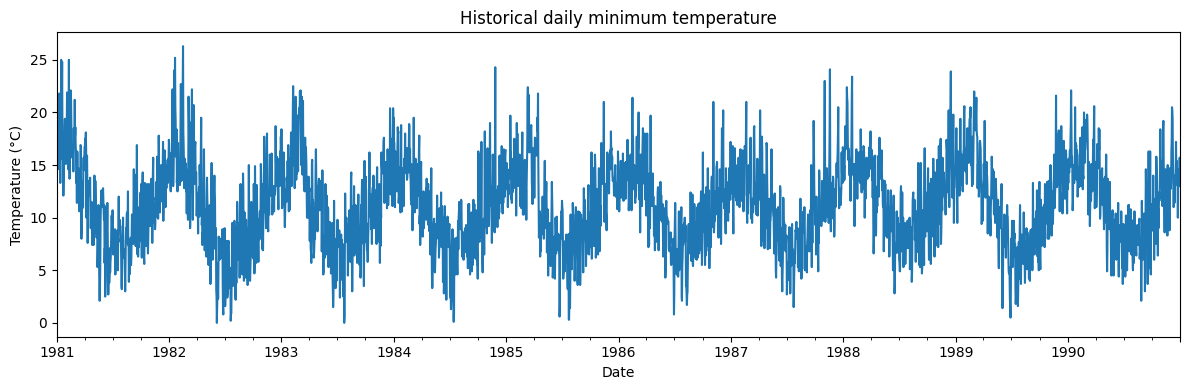

In [25]:
df['Temp'].plot(figsize=(12, 4), title='Historical daily minimum temperature')
plt.ylabel('Temperature (°C)'); plt.tight_layout(); plt.show()


In [26]:
data = df.copy()
for lag in [1, 2, 3, 7]:
    data[f'lag_{lag}'] = data['Temp'].shift(lag)
past = data['Temp'].shift(1)
data['mean_7'] = past.rolling(7).mean()
data['std_7'] = past.rolling(7).std()
data['month_sin'] = np.sin(2*np.pi*data.index.month/12)
data['month_cos'] = np.cos(2*np.pi*data.index.month/12)
data['day_sin'] = np.sin(2*np.pi*data.index.dayofyear/365.25)
data['day_cos'] = np.cos(2*np.pi*data.index.dayofyear/365.25)
data = data.dropna()
FEATURES = ['lag_1','lag_2','lag_3','lag_7','mean_7','std_7',
            'month_sin','month_cos','day_sin','day_cos']
X = data[FEATURES]


In [27]:
y = data['Temp']


In [28]:
split = int(len(data)*0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
print('Train:', X_train.index.min().date(), 'to', X_train.index.max().date(), len(X_train))
print('Test :', X_test.index.min().date(), 'to', X_test.index.max().date(), len(X_test))
assert X_train.index.max() < X_test.index.min()


Train: 1981-01-08 to 1988-12-27 2903
Test : 1988-12-28 to 1990-12-31 726


In [29]:
model = RandomForestRegressor( min_samples_leaf=5, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)


                        MAE    RMSE      R2
RandomForest         1.6784  2.1373  0.7279
PersistenceBaseline  1.9449  2.4741  0.6354


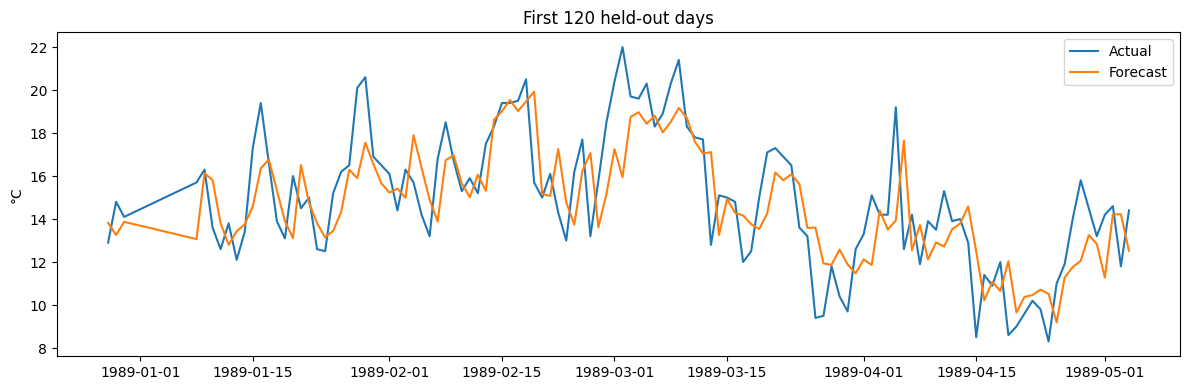

In [30]:
baseline = X_test['lag_1'].to_numpy()
def scores(actual, predicted):
    return {'MAE':float(mean_absolute_error(actual,predicted)),
            'RMSE':float(np.sqrt(mean_squared_error(actual,predicted))),
            'R2':float(r2_score(actual,predicted))}
metrics = {'RandomForest':scores(y_test,pred), 'PersistenceBaseline':scores(y_test,baseline)}
print(pd.DataFrame(metrics).T.round(4))
# MAE/RMSE are errors in °C (lower is better); R² is not accuracy.
plt.figure(figsize=(12,4))
plt.plot(y_test.index[:120],y_test.iloc[:120],label='Actual')
plt.plot(y_test.index[:120],pred[:120],label='Forecast')
plt.legend(); plt.ylabel('°C'); plt.title('First 120 held-out days'); plt.tight_layout(); plt.show()


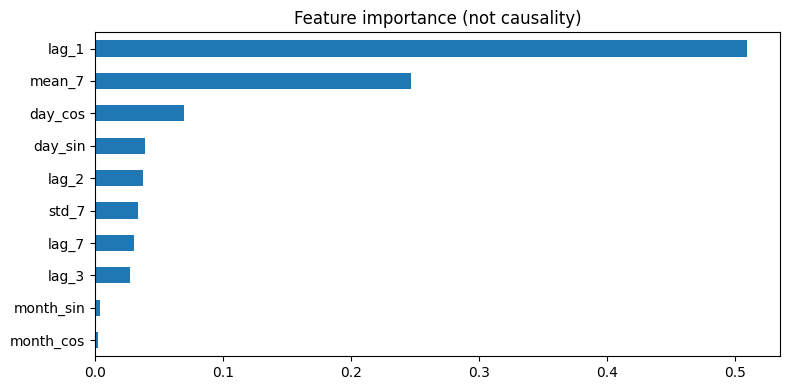

      date  actual  prediction  baseline
1988-12-28    12.9   13.825766      12.9
1988-12-29    14.8   13.259383      12.9
1988-12-30    14.1   13.868592      14.8
1989-01-08    15.7   13.067564      12.2
1989-01-09    16.3   16.126036      15.7
1989-01-10    13.6   15.812703      16.3
1989-01-11    12.6   13.803461      13.6
1989-01-12    13.8   12.800233      12.6
1989-01-13    12.1   13.430043      13.8
1989-01-14    13.4   13.751375      12.1


In [31]:
importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
importance.plot.barh(figsize=(8,4),title='Feature importance (not causality)')
plt.tight_layout(); plt.show()
results = pd.DataFrame({'date':y_test.index, 'actual':y_test.to_numpy(), 'prediction':pred, 'baseline':baseline})
results.to_csv('test_predictions.csv',index=False)
import json
Path('metrics.json').write_text(json.dumps(metrics,indent=2))
print(results.head(10).to_string(index=False))


In [32]:
print('Predicted minimum temperature:', round(float(prediction),2), '°C')


Predicted minimum temperature: 14.06 °C
